# Tema 3,  Exercițiul 1
## Problema Monty Hall

Documentația pgmpy: https://pgmpy.org/examples/Monty_Hall.html

## Modelul ca rețea Bayesiană

Avem trei variabile, fiecare cu valori $\{0, 1, 2\}$ (numărul ușii):

- $C$, ușa aleasă de concurent (uniformă, $1/3$ fiecare)
- $P$, ușa cu premiul (uniformă, $1/3$ fiecare)
- $M$, ușa deschisă de Monty

$C$ și $P$ sunt independente. $M$ depinde de ambele: Monty nu deschide niciodată ușa aleasă de concurent ($C$) și nici ușa cu premiul ($P$).

$$C \rightarrow M, \qquad P \rightarrow M$$

Pentru o rețea Bayesiană:

$$P(X_1, \dots, X_n) = \prod_{i=1}^{n} P\big(X_i \mid \text{Parinti}(X_i)\big)$$

$$P(C, P, M) = P(C)\,P(P \mid C)\,P(M \mid C, P)$$

Folosim independențele din graf: $P(P \mid C) = P(P)$

$$P(C, P, M) = P(C)\,P(P)\,P(M \mid C, P)$$

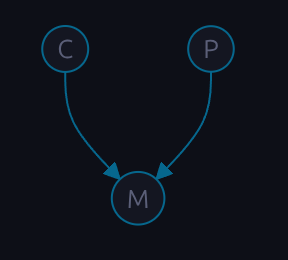

**Tabelul $P(M \mid C, P)$.** Pentru fiecare pereche $(C, P)$:

- dacă $C = P$ (concurentul a nimerit premiul), Monty poate deschide oricare dintre celelalte două uși, deci $1/2$ fiecare;
- dacă $C \neq P$, Monty este obligat să deschidă singura ușă rămasă (nici $C$, nici $P$), deci probabilitate $1$.

## Explicarea codului din implementare

Codul de mai jos (din documentația pgmpy) construiește rețeaua, definește cele trei CPD-uri și folosește eliminarea variabilelor pentru a calcula $P(P \mid C, M)$, adică unde se află premiul, știind ce a ales concurentul și ce ușă a deschis Monty.

In [1]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

# Structura: alegerea C si premiul P influenteaza usa deschisa M
model = DiscreteBayesianNetwork([("C", "M"), ("P", "M")])

/home/stefan/Laboratoare/PMP/PMP-2026/.venv/lib/python3.12/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Apoi CPD-urile. $C$ și $P$ nu au părinți (o singură coloană, uniformă); $M$ are doi părinți, deci câte o coloană pentru fiecare pereche $(C, P)$.

In [ ]:
cpd_C = TabularCPD("C", 3,
    [[1/3],   # P(C=0)
     [1/3],   # P(C=1)
     [1/3]])  # P(C=2)
cpd_P = TabularCPD("P", 3,
    [[1/3],   # P(P=0)
     [1/3],   # P(P=1)
     [1/3]])  # P(P=2)

# P(M | C, P): un rand = usa deschisa de Monty, o coloana = o pereche (C, P).
# Coloanele parcurg (C, P), ultimul parinte (P) variaza cel mai repede:
# C=0,P=0  C=0,P=1  C=0,P=2  C=1,P=0  C=1,P=1  C=1,P=2  C=2,P=0  C=2,P=1  C=2,P=2
cpd_M = TabularCPD(
    "M", 3,
    [[0,   0,   0,   0,   0.5, 1,   0,   1,   0.5],   # P(M=0 | C, P)
     [0.5, 0,   1,   0,   0,   0,   1,   0,   0.5],   # P(M=1 | C, P)
     [0.5, 1,   0,   1,   0.5, 0,   0,   0,   0  ]],  # P(M=2 | C, P)
    evidence=["C", "P"], evidence_card=[3, 3],
)

Atașăm CPD-urile și verificăm modelul.

In [3]:
model.add_cpds(cpd_C, cpd_P, cpd_M)
print("model valid:", model.check_model())

model valid: True


In [4]:
# Concurentul alege usa 0, Monty deschide usa 2. Unde e premiul?
inf = VariableElimination(model)
post = inf.query(["P"], evidence={"C": 0, "M": 2}, show_progress=False)
print(post)

+------+----------+
| P    |   phi(P) |
+======+==========+
| P(0) |   0.3333 |
+------+----------+
| P(1) |   0.6667 |
+------+----------+
| P(2) |   0.0000 |
+------+----------+


## Interpretare

Rezultatul este $P(P=0 \mid C=0, M=2) = 1/3$ și $P(P=1 \mid C=0, M=2) = 2/3$.

Dacă concurentul rămâne la ușa aleasă (ușa 0), câștigă cu probabilitate $1/3$. Dacă schimbă la ușa 1, câștigă cu probabilitate $2/3$. Deci schimbarea ușii dublează șansele de câștig.